<a href="https://colab.research.google.com/github/cleberfmodesto/llamaIndex_integracao_de_LLMs_com_bancos_de_dados_vetoriais/blob/main/Projeto_final.ipynb" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-Colab-F9AB00?labelColor=F9AB00&logo=googlecolab&logoColor=white" alt="Abrir no Colab"/></a>
<a href="https://github.com/cleberfmodesto/llamaIndex_integracao_de_LLMs_com_bancos_de_dados_vetoriais/blob/main/Projeto_final.ipynb" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-GitHub-0969DA?labelColor=0969DA&logo=github&logoColor=white" alt="Abrir GitHub"/></a>
<a href="https://github.com/codespaces/new?repo=cleberfmodesto/llamaIndex_integracao_de_LLMs_com_bancos_de_dados_vetoriais&ref=main" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-Codespaces-1F883D?labelColor=1F883D&logo=github&logoColor=white" alt="Abrir no Codespaces"/></a>


# Aula 1 - Aplicando LLM na recomendação de livros

Apresentação do problema da buscando. Utilização do Llamaindex e da LLM para recomendação de livros.

## Vídeo 1.1 - Apresentação

## Vídeo 1.2 - Utilizando LLMs com Llamaindex

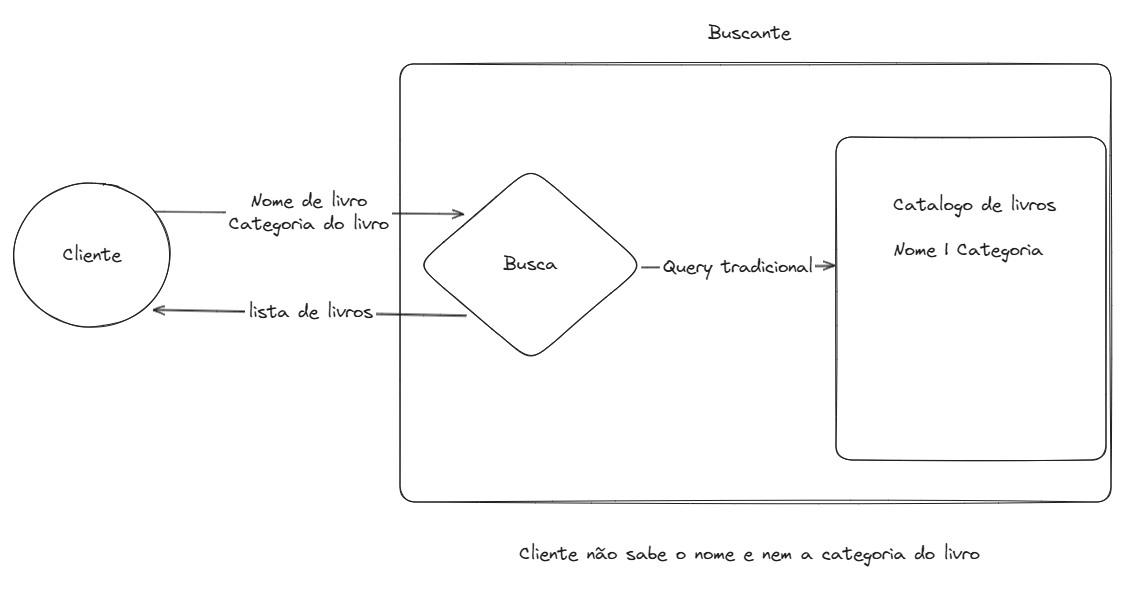

In [1]:
import os
import requests
import pandas as pd
from dotenv import load_dotenv


In [2]:
# Carrega as variáveis de ambiente do arquivo .env e api-key
load_dotenv()
key = os.environ.get("GROQ_API_KEY")

# Faz a requisição para a API da Groq para obter os modelos disponíveis

url = "https://api.groq.com/openai/v1/models"

headers = {
    "Authorization": f"Bearer {key}",
    "Content-Type": "application/json"
}

response = requests.get(url, headers=headers)
dados = response.json()["data"]

# Cria o DataFrame a partir da lista 'data'
df = pd.DataFrame(dados)

# Converte o timestamp Unix para data legível e ordena pelo ID do modelo
df["created"] = pd.to_datetime(df["created"], unit="s").dt.strftime("%Y-%m-%d")
df = df[["id", "owned_by", "context_window", "max_completion_tokens", "active", "created"]]
df = df.sort_values("id").reset_index(drop=True)

# No Jupyter,

df

,id,owned_by,context_window,max_completion_tokens,active,created
0,allam-2-7b,SDAIA,4096,4096,True,2025-01-23
1,canopylabs/orpheus-arabic-saudi,Canopy Labs,4000,50000,True,2025-12-16
2,canopylabs/orpheus-v1-english,Canopy Labs,4000,50000,True,2025-12-19
3,meta-llama/llama-prompt-guard-2-22m,Meta,512,512,True,2025-05-30
4,meta-llama/llama-prompt-guard-2-86m,Meta,512,512,True,2025-05-30
5,openai/gpt-oss-120b,OpenAI,131072,65536,True,2025-08-05
6,openai/gpt-oss-20b,OpenAI,131072,65536,True,2025-08-05
7,openai/gpt-oss-safeguard-20b,OpenAI,131072,65536,True,2025-10-29
8,qwen/qwen3.8-27b,Alibaba Cloud,131072,16384,True,2026-08-17
9,whisper-large-v3,OpenAI,448,448,True,2023-09-03


In [3]:
!pip install llama-index -q
!pip install llama-index-llms-groq -q

In [4]:
from llama_index.llms.groq import Groq

llm = Groq(model="openai/gpt-oss-120b", api_key=key)

In [5]:
from llama_index.core.chat_engine import SimpleChatEngine

chat_engine = SimpleChatEngine.from_defaults(llm=llm)
chat_engine.chat_repl()

===== Entering Chat REPL =====
Type "exit" to exit.

Assistant: A próxima eleição presidencial nos Estados Unidos está marcada para **terça‑feira, 5 de novembro de 2024**.  

### Como funciona o calendário eleitoral dos EUA

| Etapa | Período aproximado | O que acontece |
|-------|--------------------|----------------|
| **Primárias e caucuses** (seleção dos candidatos dos partidos) | Fevereiro – Junho 2024 | Cada estado realiza primárias ou caucuses para escolher delegados que irão votar nos candidatos nas convenções nacionais. |
| **Convenções nacionais** (nominação oficial dos candidatos) | Julho – Agosto 2024 | Os partidos Democrata e Republicano oficializam seus candidatos à presidência e escolhem o candidato a vice‑presidente. |
| **Campanha geral** | Setembro – Novembro 2024 | Os candidatos viajam, participam de debates e fazem propaganda até o dia da eleição. |
| **Eleição geral** | **5 de novembro de 2024** | Eleitores de todos os 50 estados e do Distrito de Columbia votam. O 

## Vídeo 1.3 - Recomendando livros com LLMs

In [6]:
llm.complete("Consegue me ajudar com duvidas literarias ?")

CompletionResponse(text='Claro! Estou à disposição para esclarecer dúvidas sobre literatura. Seja sobre autores, obras, movimentos literários, técnicas de escrita, análise de textos ou qualquer outro assunto relacionado, é só me dizer qual é a sua pergunta que eu ajudo. 😊', additional_kwargs={'prompt_tokens': 81, 'completion_tokens': 104, 'total_tokens': 185}, raw=ChatCompletion(id='chatcmpl-1e6d4595-8683-4a09-8eeb-288172d5079b', choices=[Choice(finish_reason='stop', index=0, logprobs=None, message=ChatCompletionMessage(content='Claro! Estou à disposição para esclarecer dúvidas sobre literatura. Seja sobre autores, obras, movimentos literários, técnicas de escrita, análise de textos ou qualquer outro assunto relacionado, é só me dizer qual é a sua pergunta que eu ajudo. 😊', refusal=None, role='assistant', annotations=None, audio=None, function_call=None, tool_calls=None, reasoning='The user asks in Portuguese: "Consegue me ajudar com dúvidas literárias?" (Can you help me with literary 

In [7]:
llm.complete("Recomende livros de romance")

CompletionResponse(text='Claro! Aqui vai uma seleção variada de romances (ficção romântica) que agradam diferentes gostos, desde clássicos atemporais até obras contemporâneas e de autores de língua portuguesa. Cada título inclui uma breve sinopse para ajudar na escolha.\n\n---\n\n## 1. Clássicos da literatura romântica\n\n| Título | Autor | Ano | Por que ler |\n|--------|-------|-----|-------------|\n| **Orgulho e Preconceito** | Jane Austen | 1813 | Uma das histórias de amor mais queridas da literatura, com humor, crítica social e personagens inesquecíveis (Elizabeth Bennet e Mr. Darcy). |\n| **Jane Eyre** | Charlotte Brontë | 1847 | Romance gótico que combina paixão, independência feminina e questões morais; a relação entre Jane e o misterioso Mr. Rochester é icônica. |\n| **O Morro dos Ventos Uivados** | Emily Brontë | 1847 | Amor obsessivo e tormentoso entre Heathcliff e Catherine, ambientado nas sombrias charnecas de Yorkshire. |\n| **Anna Karenina** | Liev Tolstói | 1877 | Um épi

In [8]:
resposta = llm.complete("Recomende livros de romance")

In [9]:
print(resposta.text)

Claro! Aqui vai uma lista variada de romances (ficção romântica) que agradam diferentes gostos, com breves sinopses para ajudar na escolha. Incluí obras clássicas, contemporâneas, brasileiras e traduções internacionais.

---

## 1. **Clássicos imperdíveis**

| Título | Autor | Ano | Por que ler |
|--------|-------|-----|-------------|
| **Orgulho e Preconceito** | Jane Austen | 1813 | Um dos romances mais amados da literatura inglesa. A sagaz Elizabeth Bennet e o orgulhoso Sr. Darcy criam um duelo de inteligência e sentimentos que ainda ressoa hoje. |
| **Jane Eyre** | Charlotte Brontë | 1847 | Uma narrativa gótica que combina romance, independência feminina e crítica social. A relação entre Jane e o misterioso Sr. Rochester é intensa e cheia de reviravoltas. |
| **Cem Anos de Solidão** | Gabriel García Márquez | 1967 | Embora seja mais conhecido como realismo mágico, o romance central entre Fernanda e Aureliano (e outras gerações) oferece uma visão épica do amor ao longo de um século.

# Aula 2 - Construindo recomendações que existem na base de dados

Restrigindo a recomendação da LLM fornecendo a base de dados da empresa. Aplicando tecnica de summarize para limitar conteudo apresentado a LLM.

## Vídeo 2.1 - Passando toda a base de livros a LLM

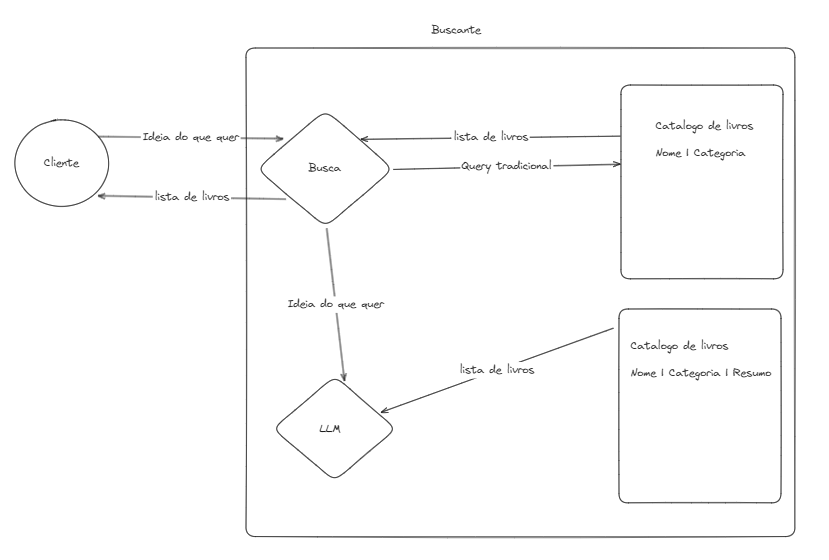

In [10]:
import pandas as pd

df = pd.read_csv("https://raw.githubusercontent.com/cleberfmodesto/llamaIndex_integracao_de_LLMs_com_bancos_de_dados_vetoriais/refs/heads/main/csv/livros_mais_vendidos.csv")

In [11]:
df.head()

,nome,categoria,sinopse,preco
0,É ASSIM QUE COMEÇA (EDIÇÃO DE COLECIONADOR),Romances,Todo final tem um começo. Agora em uma edição ...,"R$ 94,90"
1,TUDO É RIO,Romances,NaN,"R$ 71,39"
2,VERITY (EDIÇÃO DE COLECIONADOR),Suspenses,Um casal apaixonado. Uma intrusa. Três mentes ...,"R$ 79,90"
3,TÁTICAS DO AMOR,Romances,"Febre no TikTok, comédia romântica narra a ami...","R$ 65,89"
4,NEM TE CONTO,Romances,Da autora best seller do \r\n ...,"R$ 59,90"


In [12]:
print("Numero de registros: ",len(df))

Numero de registros:  175


In [13]:
prompt = "Só recomende livros dessa base de dados:"

for linha in df.values:
  prompt += f"\n{linha[0]}"

In [14]:
entrada_user = "Me recomende livros de romance ?"

In [15]:
len(prompt)

4470

In [16]:
resposta = llm.complete(prompt=prompt+entrada_user).text
print(resposta)

**Romances disponíveis na sua lista**  

Abaixo selecionei os títulos que, pelo título, sinopse ou classificação conhecida, são claramente romances (ou têm forte componente romântico). Para cada um incluí um breve resumo e o motivo pelo qual vale a pena ler.

| # | Título | Tipo de romance | Por que ler |
|---|--------|----------------|-------------|
| 1 | **É ASSIM QUE COMEÇA** (Edição de Colecionador) | Romance contemporâneo / “new adult” | História de reencontro e segundas chances, com personagens bem construídos e diálogos afiados. Ideal para quem curte narrativas de crescimento pessoal e amor inesperado. |
| 2 | **É ASSIM QUE ACABA** | Romance contemporâneo | Continuação de *É ASSIM QUE COMEÇA*, traz conflitos mais intensos e amadurecimento dos protagonistas. Boa pedida para quem já se apegou ao primeiro volume. |
| 3 | **TUDO É RIO** | Romance leve / comédia romântica | Uma trama divertida que mistura humor e romance, perfeita para leituras descontraídas. |
| 4 | **VERITY** (Ediç

## Vídeo 2.2 - Fazendo recomendação mais precisas

In [17]:
prompt = """
Somente responda em json
Formato resposta em json
[data:{
  "livros": [
    {
      "titulo": "Titulo do livro
      "categoria": "Categoria do livro"
      "Justificativa" "Porque recomenda"
    }
  ]
}]
Só recomende livros dessa base de dados:

"""

In [18]:
for linha in df.values:
  prompt += f"\n{linha[0]}"

In [19]:
resposta = llm.complete(prompt=prompt+entrada_user).text
print(resposta)

{
  "data": {
    "livros": [
      {
        "titulo": "É ASSIM QUE COMEÇA (EDIÇÃO DE COLECIONADOR)",
        "categoria": "Romance",
        "Justificativa": "Um romance contemporâneo que mistura humor e drama, ideal para quem busca uma história de amor com reviravoltas inesperadas."
      },
      {
        "titulo": "É ASSIM QUE ACABA",
        "categoria": "Romance",
        "Justificativa": "Clássico moderno que explora os altos e baixos de um relacionamento intenso, oferecendo reflexões sobre amor, perda e crescimento pessoal."
      },
      {
        "titulo": "TUDO É RIO",
        "categoria": "Romance",
        "Justificativa": "Narrativa leve e divertida que combina romance com momentos de autodescoberta, perfeita para leituras descontraídas."
      },
      {
        "titulo": "VERITY (EDIÇÃO DE COLECIONADOR)",
        "categoria": "Romance / Suspense",
        "Justificativa": "Mistura romance e suspense de forma magistral, mantendo o leitor preso à trama enquanto desenvo

In [20]:
import json

# Remove delimitadores markdown de código gerados pelo LLM
limpo = resposta.replace("```json", "").replace("```", "").strip()
resposta_json = json.loads(limpo)

In [21]:
for livro in resposta_json["data"]["livros"]:
  titulo = livro.get("titulo").upper()

  if df.query("nome == @titulo").empty:
    print(f"Livro {titulo} não encontrado")

In [22]:
livro_novo =    {'titulo': 'Não existe',
      'categoria': 'Romance',
      'Justificativa': 'Um romance que vai levar você a uma jornada emocionante pela cidade do Rio de Janeiro.'}

In [23]:
resposta_json["data"]["livros"].extend([livro_novo])

In [24]:
for livro in resposta_json["data"]["livros"]:
  titulo = livro.get("titulo").upper()

  if df.query("nome == @titulo").empty:
    print(f"Livro {titulo} não encontrado")

Livro NÃO EXISTE não encontrado


# Aula 3 - Criando uma base vetorial

Utilizando a tecnica de embeding e base de dados estruturadas para refinar busca de dados a serem passadoa a LLM

## Vídeo 3.1 - Embedding dos dados

In [25]:
from llama_index.embeddings.huggingface import HuggingFaceEmbedding

/home/vscode/Alura/llamaIndex_integracao_de_LLMs_com_bancos_de_dados_vetoriais/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [26]:
# Custom wrapper class to match Chroma's expected signature
class ChromaEmbeddingWrapper:
    def __init__(self, model_name):
        self.model = HuggingFaceEmbedding(model_name=model_name)

    def __call__(self, input):
        if isinstance(input, str):
            input = [input]
        return [self.model.get_text_embedding(t) for t in input]

    def name(self):
        return "ChromaEmbeddingWrapper"

# Initialize the custom wrapper
embed_model_chroma = ChromaEmbeddingWrapper(model_name="intfloat/multilingual-e5-large")


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 2338.03it/s]


## Vídeo 3.2 - Base de dados vetorial

In [27]:
!pip install llama-index-vector-stores-chroma -q

In [28]:
import chromadb

# Inicializar o cliente persistente
db = chromadb.PersistentClient(path="./chroma_db")
chroma_client = db

# Nome da coleção
collection_name = "meus_documentos"

# Carregar a coleção, se existir; caso contrário, criá-la
chroma_collection = chroma_client.get_or_create_collection(
    name=collection_name
)


In [29]:
from llama_index.vector_stores.chroma import ChromaVectorStore
from llama_index.core import StorageContext

In [30]:
vector_store = ChromaVectorStore(chroma_collection=chroma_collection)
storage_context = StorageContext.from_defaults(vector_store=vector_store)

## Vídeo 3.3 - Montando pipeline

In [31]:
from llama_index.core import SimpleDirectoryReader

In [32]:
documents = SimpleDirectoryReader('/home/vscode/Alura/llamaIndex_integracao_de_LLMs_com_bancos_de_dados_vetoriais/csv/').load_data()

In [33]:
from llama_index.core import VectorStoreIndex

In [34]:
embed_model = HuggingFaceEmbedding(model_name="intfloat/multilingual-e5-large")

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 3479.75it/s]


In [35]:
import time

start_time = time.time()

index = VectorStoreIndex.from_documents(
    documents, storage_context=storage_context, embed_model=embed_model
)

end_time = time.time()
execution_time = end_time - start_time

# Converte os segundos para horas, minutos e segundos
tempo_formatado = time.strftime("%H:%M:%S", time.gmtime(execution_time))

print(f"Tempo de execução: {tempo_formatado}")

Tempo de execução: 00:07:06


In [36]:
from llama_index.core import load_index_from_storage

In [37]:
index = load_index_from_storage(storage_context, embed_model=embed_model)

In [38]:
query_engine = index.as_query_engine(similarity_top_k=2, llm=llm)

In [39]:
resposta = query_engine.query("Livros de romance ?").response
print(resposta)

Aqui estão os títulos que se enquadram no gênero romance:

- **IMPERFEITOS** – R$ 29,90  
- **[Livro da história de Leah e Matt]** – R$ 65,89  

Esses são os livros de romance presentes nos dados.


## Vídeo 3.4 - Buscando por TopK resultados

In [40]:
query_str = "Livros de romance"

In [41]:
query_embeded = embed_model.get_text_embedding(query_str)

In [42]:
chroma_collection.query(query_embeded, n_results=10, include=['distances', 'embeddings'])

{'ids': [['9d8a1574-f3f1-4d18-a805-356c9350e019',
   '8b611fec-00ab-4da1-943a-ee8d916b7e4b',
   '73c5a2a3-9431-45f4-b63a-6919f427e21c',
   '386dff72-6bc0-449a-9e45-320adea65008',
   'd6432cf6-1935-4b02-9d00-d708e05d2eae',
   'e7efebb0-6925-48e3-83df-881a9f3cdc73',
   'f5f6bed8-74da-4853-8ad5-419439b63daf',
   '2bc21add-59b4-411a-a1f9-a761adde1f13',
   '4207646a-56d9-4663-b6f6-a843eca57a0e',
   'f6b999a4-5f84-4004-b2ec-91cabad9c01f']],
 'embeddings': [array([[ 0.00820077, -0.01421511,  0.00361485, ..., -0.01167108,
          -0.02552286,  0.01264322],
         [ 0.01023411, -0.01196606,  0.00391765, ..., -0.01155364,
          -0.02606879,  0.01105059],
         [ 0.01074504, -0.01166651,  0.00555746, ..., -0.01136   ,
          -0.02661248,  0.01128007],
         ...,
         [ 0.02150715, -0.00389918, -0.02239741, ..., -0.00133584,
          -0.00987323,  0.03225204],
         [ 0.02150715, -0.00389918, -0.02239741, ..., -0.00133584,
          -0.00987323,  0.03225204],
         [ 0.

In [43]:
# Obter IDs de todos os documentos
doc_ids = chroma_collection.get()['ids']
print(f"Total de IDs: {len(doc_ids)}")
print("Amostra de IDs:", doc_ids[:5])  # Exibe os primeiros 5 IDs para inspecionar

# Extrair uma amostra dos documentos
amostra = chroma_collection.get([doc_ids[i] for i in range(5)])  # Ajuste o número se quiser mais amostras
print("Amostra de documentos:", amostra)

Total de IDs: 430
Amostra de IDs: ['d202f784-d864-43a5-a735-06d171fe1643', '1f9bd101-8a04-4f4d-8c09-fb39a70f286d', 'ac1263a5-a713-429f-a7ab-1dd94d77577a', '0a69443b-338a-4062-acfc-68d768b38a0f', '5a79115b-6e46-4578-96dd-04cf8e57e3eb']
Amostra de documentos: {'ids': ['d202f784-d864-43a5-a735-06d171fe1643', '1f9bd101-8a04-4f4d-8c09-fb39a70f286d', 'ac1263a5-a713-429f-a7ab-1dd94d77577a', '0a69443b-338a-4062-acfc-68d768b38a0f', '5a79115b-6e46-4578-96dd-04cf8e57e3eb'], 'embeddings': None, 'documents': ['PK\x03\x04\x14\x00\x00\x00\x00\x00,X}Y\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x08\x00 \x00Artigos/UT\r\x00\x074IgtIg3Igux\x0b\x00\x01\x04\x00\x00\x00\x00\x04\x00\x00\x00\x00PK\x03\x04\x14\x00\x08\x00\x08\x00+X}Y\x00\x00\x00\x00\x00\x00\x00\x00\x06\x00\x00\x1d\x00 \x00Artigos/artigo_0 - 3 anos.txtUT\r\x00\x073Ig\x19Ig0\x12ux\x0b\x00\x01\x04\x00\x00\x00\x00\x04\x00\x00\x00\x00UKn#7\x10\x0f0wxm7\x02\x04 \nb+\x00ATi\x18ss\x01!\x17d-/6-K\n +QTT?JNϖ\x03\x13GjaW>ae \x1b<3I*;8\'q)\x08}KB\x11

In [44]:
chroma_collection.get("d202f784-d864-43a5-a735-06d171fe1643")

{'ids': ['d202f784-d864-43a5-a735-06d171fe1643'],
 'embeddings': None,
 'documents': ['PK\x03\x04\x14\x00\x00\x00\x00\x00,X}Y\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x08\x00 \x00Artigos/UT\r\x00\x074IgtIg3Igux\x0b\x00\x01\x04\x00\x00\x00\x00\x04\x00\x00\x00\x00PK\x03\x04\x14\x00\x08\x00\x08\x00+X}Y\x00\x00\x00\x00\x00\x00\x00\x00\x06\x00\x00\x1d\x00 \x00Artigos/artigo_0 - 3 anos.txtUT\r\x00\x073Ig\x19Ig0\x12ux\x0b\x00\x01\x04\x00\x00\x00\x00\x04\x00\x00\x00\x00UKn#7\x10\x0f0wxm7\x02\x04 \nb+\x00ATi\x18ss\x01!\x17d-/6-K\n +QTT?JNϖ\x03\x13GjaW>ae \x1b<3I*;8\'q)\x08}KB\x11;\x1fG\x10\rҚȖ"\x02s\n˂\x1b}0\x1dn\x08=]+&jz=uodև"xAT>ٯYw\x17K˼6˧GLhQqL2\x03N.A\x00uId+N7Zy\nI3Gy=%\x14I137\x1d+\n$C7߽\x7f\x04\n\x13\x18\x001\x1eu5~y\x17?.~[\\~y^/i~|l次y\x04\x13c\x00ϖGv}\x1cV\x10˲9S->Gp\x0fr瞕l)3`\x1c?UcCy\x1aE!T2\x1d\\c"O`\\\x01`M@8\x02pr~j+F)\x1bn#\'$8+(1aCK`SP-w*\x1f\rV"\x07&\x04«K\x18\x17:Zl\x15ǲs\x1e\x1enft=j\x065.\x17?-\x0fsrvO7nv\x7f6\x7f4p11/\x00:\x19Ex}-)ʊJvĦ5\x1f,XK\x1bEh\x0b\x0bH\x1c\x1

# Aula 4 - Nova fonte de dados

## Vídeo 4.1 - Carregando dados da base não estruturada

In [47]:
novos_documentos = SimpleDirectoryReader("../Artigos").load_data()

In [48]:
end_time = time.time()

for doc in novos_documentos:
    index.insert(doc)

execution_time = end_time - start_time

print(f"Tempo de execução: {execution_time} segundos")

Tempo de execução: 771.7175068855286 segundos


In [49]:
# Obter IDs de todos os documentos
doc_ids = chroma_collection.get()['ids']
print(f"Total de IDs: {len(doc_ids)}")

Total de IDs: 471


In [50]:
query_str = "Livros de romance"

In [51]:
query_embeded = embed_model.get_text_embedding(query_str)

In [52]:
chroma_collection.query(query_embeded, n_results=10, include=['distances'])

{'ids': [['0755dc3c-3a09-4c76-9ac6-7bd1c6083f85',
   '5a1988db-d1df-4162-85e1-eca0e666a494',
   '9d8a1574-f3f1-4d18-a805-356c9350e019',
   '8b611fec-00ab-4da1-943a-ee8d916b7e4b',
   '73c5a2a3-9431-45f4-b63a-6919f427e21c',
   '386dff72-6bc0-449a-9e45-320adea65008',
   'd6432cf6-1935-4b02-9d00-d708e05d2eae',
   'e7efebb0-6925-48e3-83df-881a9f3cdc73',
   'f5f6bed8-74da-4853-8ad5-419439b63daf',
   '2bc21add-59b4-411a-a1f9-a761adde1f13']],
 'embeddings': None,
 'documents': None,
 'uris': None,
 'included': ['distances'],
 'data': None,
 'metadatas': None,
 'distances': [[0.3575572073459625,
   0.36361509561538696,
   0.36401161551475525,
   0.3650789260864258,
   0.3656820058822632,
   0.3656820058822632,
   0.3656820058822632,
   0.3666035234928131,
   0.36697787046432495,
   0.36697787046432495]]}

## Vídeo 4.2 - Consulta multidocumento

In [53]:
retriever = index.as_retriever()

In [54]:
from llama_index.core import get_response_synthesizer

In [55]:
synthesizer = get_response_synthesizer(response_mode="compact", llm=llm)

In [56]:
from llama_index.core import PromptTemplate

In [57]:
qa_prompt = PromptTemplate(
    "Context information is below.\n"
    "---------------------\n"
    "{context_str}\n"
    "---------------------\n"
    "Given the context information and not prior knowledge, "
    "answer the query.\n"
    "Responda em português.\n"
    """Somente responda em json
      Formato resposta em json
      {"data":{
        "livros": [
          {
            "titulo": "Titulo do livro
            "categoria": "Categoria do livro"
            "Justificativa" "Porque recomenda"
          }
        ]
      }}

      Só recomende livros dessa base de dados"""
    "Query: {query_str}\n"
    "Answer: "
)

In [58]:
from llama_index.core.query_engine import CustomQueryEngine
from llama_index.core.retrievers import BaseRetriever
from llama_index.core.response_synthesizers import BaseSynthesizer

In [59]:
class RAGStringQueryEngine(CustomQueryEngine):

    retriever: BaseRetriever
    response_synthesizer: BaseSynthesizer
    llm: Groq
    qa_prompt: PromptTemplate

    def custom_query(self, query_str: str):
        nodes = self.retriever.retrieve(query_str)

        context_str = "\n\n".join([n.node.get_content() for n in nodes])

        response = self.llm.complete(
            self.qa_prompt.format(context_str=context_str, query_str=query_str)
        )

        return str(response)

In [60]:
query_engine_customize = RAGStringQueryEngine(
    retriever=retriever,
    response_synthesizer=synthesizer,
    llm=llm,
    qa_prompt=qa_prompt
)

In [61]:
resposta = query_engine_customize.query("Quais livros de Romance").response
print(resposta)

{
  "data": {
    "livros": [
      {
        "titulo": "NEM TE CONTO",
        "categoria": "Romances",
        "Justificativa": "Romance leve e divertido da best‑seller Emily Henry, com personagens opostos que criam situações engraçadas e emocionantes, ideal para quem busca uma comédia romântica cheia de charme e diálogos espirituosos."
      },
      {
        "titulo": "O BEIJO DA NEVE",
        "categoria": "Romances",
        "Justificativa": "Romance emocionante sobre Nina e Elyan, patinadores cujas diferenças se transformam em química irresistível, perfeito para quem gosta de histórias de superação, paixão e um toque de drama esportivo."
      }
    ]
  }
}


In [62]:
# Remove delimitadores markdown de código gerados pelo LLM
limpo = resposta.replace("```json", "").replace("```", "").strip()
resposta_json = json.loads(limpo)

In [63]:
for livro in resposta_json["data"]["livros"]:
  titulo = livro.get("titulo").upper()

  if df.query("nome == @titulo").empty:
    print(f"Livro {titulo} não encontrado")

# Aula 5 - Publicando MVP

Montando pipeline do que foi construido até agora e disponibilizando um MVP do projeto.

## Vídeo 5.1 - Preparando pipeline

In [64]:
def validando(resposta_json):
  for livro in resposta_json["data"]["livros"]:
    titulo = livro.get("titulo").upper()

  if df.query("nome.str.contains(@titulo)").empty:
    raise Exception(f"Livro {titulo} não encontrado")


In [65]:
def formatando_respostas(response, consulta):
  prompt = f'''
  Formate a resposta para o usuario
  Sua persona é um atendente da empresa buscante que vai recomendar livros usando a consulta do usuario como referencia
  E recomendar somente esses livros que estão em response
  consulta: {consulta}
  response: {response}
  '''
  resposta_final = llm.complete(prompt=prompt).text
  return resposta_final

In [66]:
def pipeline_completo(consulta):
    response = query_engine_customize.query(consulta).response
    limpo = response.replace("```json", "").replace("```", "").strip()
    resposta_json = json.loads(limpo)

    validando(resposta_json)

    #formatar a resposta
    response = formatando_respostas(response, consulta)

    return str(response)


In [71]:
print(pipeline_completo("Quais livros de Romance ?"))

Olá! 😊  
Com base na sua consulta, separei os melhores títulos de **Romance** que temos disponíveis. Cada sugestão vem acompanhada de uma breve justificativa para ajudar na sua escolha.

---

### 📚 Livros de Romance recomendados

| Título | Por que você vai gostar |
|--------|------------------------|
| **É ASSIM QUE COMEÇA (EDIÇÃO DE COLECIONADOR)** | História de amor tradicional que agrada leitores que buscam um romance clássico e envolvente. |
| **TUDO É RIO** | Narrativa leve e divertida, ideal para quem quer se divertir com personagens cativantes. |
| **TÁTICAS DO AMOR** | Romance descontraído que combina humor e romance, conquistando o coração dos leitores. |
| **NEM TE CONTO** | História intensa e emocional, perfeita para quem gosta de dramas apaixonados. |
| **O BEIJO DA NEVE** | Romance intenso que entrega fortes emoções e reviravoltas apaixonantes. |
| **EU E ESSE MEU CORAÇÃO** | Narrativa profunda e emotiva, indicada para leitores que apreciam romances intensos. |
| **A MAND

## Vídeo 5.2 - Subindo aplicação Gradio

In [72]:
!pip install -q gradio

In [73]:
import gradio as gr

demo = gr.Interface(
    fn=pipeline_completo,
    inputs=["text"],
    outputs=["text"],
)

demo.launch(debug=True)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Traceback (most recent call last):
  File "/home/vscode/Alura/llamaIndex_integracao_de_LLMs_com_bancos_de_dados_vetoriais/.venv/lib/python3.10/site-packages/gradio/queueing.py", line 870, in process_events
    response = await route_utils.call_process_api(
  File "/home/vscode/Alura/llamaIndex_integracao_de_LLMs_com_bancos_de_dados_vetoriais/.venv/lib/python3.10/site-packages/gradio/route_utils.py", line 418, in call_process_api
    output = await app.get_blocks().process_api(
  File "/home/vscode/Alura/llamaIndex_integracao_de_LLMs_com_bancos_de_dados_vetoriais/.venv/lib/python3.10/site-packages/gradio/blocks.py", line 2698, in process_api
    result = await self.call_function(
  File "/home/vscode/Alura/llamaIndex_integracao_de_LLMs_com_bancos_de_dados_vetoriais/.venv/lib/python3.10/site-packages/gradio/blocks.py", line 1963, in call_function
    prediction = await anyio.to_thread.run_sync(  # type: ignore
  File "/home/vscode/Alura/llamaIndex_integracao_de_LLMs_com_bancos_de_dados_v

Created dataset file at: .gradio/flagged/dataset1.csv
Keyboard interruption in main thread... closing server.


## Vídeo 5.3 - Conclusão